In [3]:
import cudf
import cuml
import cupy as cp
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.model_selection import train_test_split
from sklearn.model_selection import KFold
from cuml.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from cuml.decomposition import PCA
from cuml.cluster import DBSCAN
from cuml.neighbors import NearestNeighbors
from sklearn.metrics import (confusion_matrix, precision_score, 
                           recall_score, f1_score, accuracy_score,
                           roc_auc_score)
from sklearn.model_selection import ParameterGrid
import numpy as np
import warnings
import kagglehub
warnings.filterwarnings('ignore')

cuml.set_global_output_type('cupy')

def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], 
                yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

def print_confusion_matrix(cm, title):
    print(f"{title}:")
    print("         Predicted")
    print("         Not Fraud  Fraud")
    print(f"Actual")
    print(f"Not Fraud  {cm[0,0]:6d}  {cm[0,1]:6d}")
    print(f"Fraud      {cm[1,0]:6d}  {cm[1,1]:6d}")

def plot_pca_clusters(pca_df, title):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', 
                    data=pca_df.to_pandas(), palette='viridis')
    plt.title(title)
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()

def load_and_preprocess_data():
    path = kagglehub.dataset_download("ealaxi/banksim1")
    data = cudf.read_csv(path + '/bs140513_032310.csv')
    
    data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
    for col in ['customer', 'age', 'gender', 'merchant']:
        data[col] = data[col].str[1:-1]
    data['category'] = data['category'].str.replace('es_', '')
    data = data[data['gender'] != 'U']
    data['age'] = data['age'].replace('U', '7').astype('float32')
    data['amount'] = data['amount'].astype('float32')
    
    bins = [0, 500, 1000, 1500, 2000, 2500, 3000, float('inf')]
    labels = ['0-500', '500-1000', '1000-1500', '1500-2000', 
              '2000-2500', '2500-3000', '>3000']
    data['amount_thresh'] = cudf.cut(data['amount'], bins=bins, labels=labels)
    
    for entity in ['customer', 'merchant', 'category', 'amount_thresh']:
        freq = data.groupby(entity).size().reset_index(name=f'{entity}_freq')
        freq[f'{entity}_ID'] = cp.arange(1, len(freq) + 1)
        data = data.merge(freq, on=entity)
        if entity in ['customer', 'merchant']:
            data = data.drop(entity, axis=1)
        else:
            data[entity] = data[f'{entity}_ID']
            data = data.drop(f'{entity}_ID', axis=1)
    
    total = len(data)
    for col in data.columns:
        if '_freq' in col:
            data[col] = (data[col] / total * 100).round(5)
    
    ohe = OneHotEncoder(sparse=True, handle_unknown='ignore')
    ohe_cols = ['age', 'gender', 'category', 'amount_thresh']
    ohe_data = ohe.fit_transform(data[ohe_cols])
    ohe_data = cudf.DataFrame(ohe_data.toarray(), 
                             columns=ohe.get_feature_names(ohe_cols))
    data = cudf.concat([data.drop(ohe_cols, axis=1), ohe_data], axis=1)
    
    le = LabelEncoder()
    data['fraud'] = le.fit_transform(data['fraud'])
    
    return data

def evaluate_dbscan(params, X, y, n_splits=5):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X).astype('float32')
    y = y.astype('int32')
    
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=123)
    fold_metrics = []
    
    for fold, (train_idx, test_idx) in enumerate(kf.split(X)):
        train_idx = cp.array(train_idx)
        test_idx = cp.array(test_idx)
        
        X_train = X_scaled[train_idx]
        y_train = y.iloc[train_idx]
        X_test = X_scaled[test_idx]
        y_test = y.iloc[test_idx]
        
        dbscan = DBSCAN(eps=params['eps'],
                       min_samples=params['min_samples'],
                       output_type='cupy')
        
        # Fit DBSCAN on training data and get labels
        train_labels = dbscan.fit_predict(X_train)
        
        # Identify core points and their labels
        core_mask = dbscan.core_sample_indices_
        if len(core_mask) == 0:
            # If no core points, assign all test points as noise (-1)
            test_labels = cp.full(X_test.shape[0], -1, dtype='int32')
        else:
            # Get core points and their cluster labels
            core_points = X_train[core_mask]
            core_labels = train_labels[core_mask]
            
            # Use NearestNeighbors to assign test points to the nearest core point's cluster
            nn = NearestNeighbors(n_neighbors=1)
            nn.fit(core_points)
            _, indices = nn.kneighbors(X_test)
            test_labels = core_labels[cp.array(indices.flatten())]
        
        def analyze_clusters(labels, true_labels):
            clusters = cudf.DataFrame({'cluster': labels, 'true_label': true_labels})
            stats = []
            unique_clusters = cp.unique(labels)
            for cluster in unique_clusters.get():
                if cluster == -1:
                    continue
                mask = clusters['cluster'] == cluster
                fraud_ratio = clusters[mask]['true_label'].mean().item()
                size = mask.sum().item()
                stats.append({
                    'cluster': cluster,
                    'fraud_ratio': fraud_ratio,
                    'size': size
                })
            return cudf.DataFrame(stats)
        
        train_stats = analyze_clusters(train_labels, y_train)
        cluster_mapping = {}
        for i in range(len(train_stats)):
            cluster = train_stats['cluster'].iloc[i].item()
            fraud_ratio = train_stats['fraud_ratio'].iloc[i].item()
            cluster_mapping[cluster] = 1 if fraud_ratio > params['fraud_threshold'] else 0
        cluster_mapping[-1] = 0
        
        def evaluate(y_true, labels, name, fold):
            pred = cudf.Series(labels).map(cluster_mapping).fillna(0)
            y_true_np = cp.asnumpy(y_true.values)
            y_pred_np = cp.asnumpy(pred.values)
            
            metrics = {
                'cm': confusion_matrix(y_true_np, y_pred_np),
                'recall': recall_score(y_true_np, y_pred_np, zero_division=0),
                'precision': precision_score(y_true_np, y_pred_np, zero_division=0),
                'f1': f1_score(y_true_np, y_pred_np, zero_division=0),
                'accuracy': accuracy_score(y_true_np, y_pred_np),
                'auc': roc_auc_score(y_true_np, y_pred_np)
            }
            
            print(f"\n=== {name} Fold {fold} Results ===")
            print_confusion_matrix(metrics['cm'], f"{name} Fold {fold} Confusion Matrix")
            print(f"Recall: {metrics['recall']:.4f} | Precision: {metrics['precision']:.4f}")
            print(f"F1: {metrics['f1']:.4f} | AUC: {metrics['auc']:.4f}")
            
            return metrics
        
        train_metrics = evaluate(y_train, train_labels, "Training", fold)
        test_metrics = evaluate(y_test, test_labels, "Test", fold)
        
        fold_metrics.append({
            'fold': fold,
            'train_metrics': train_metrics,
            'test_metrics': test_metrics,
            'cluster_stats': train_stats
        })
    
    avg_test_metrics = {
        'recall': np.mean([m['test_metrics']['recall'] for m in fold_metrics]),
        'precision': np.mean([m['test_metrics']['precision'] for m in fold_metrics]),
        'f1': np.mean([m['test_metrics']['f1'] for m in fold_metrics]),
        'accuracy': np.mean([m['test_metrics']['accuracy'] for m in fold_metrics]),
        'auc': np.mean([m['test_metrics']['auc'] for m in fold_metrics])
    }
    
    print(f"\n=== Average Test Metrics Across {n_splits} Folds ===")
    print(f"Recall: {avg_test_metrics['recall']:.4f} | Precision: {avg_test_metrics['precision']:.4f}")
    print(f"F1: {avg_test_metrics['f1']:.4f} | AUC: {avg_test_metrics['auc']:.4f}")
    
    return {
        'params': params,
        'fold_metrics': fold_metrics,
        'avg_test_metrics': avg_test_metrics,
        'scaler': scaler,
        'model': dbscan
    }

def main():
    data = load_and_preprocess_data()
    print("Data dimensions:", data.shape)
    
    pca_cols = [col for col in data.columns if col != 'fraud']
    scaler = StandardScaler()
    pca_data = PCA(n_components=2).fit_transform(scaler.fit_transform(data[pca_cols]))
    pca_df = cudf.DataFrame(pca_data, columns=['PC1', 'PC2'])
    pca_df['fraud'] = data['fraud']
    plot_pca_clusters(pca_df, 'Fraud Spread over Principal Components')
    
    X = data.drop('fraud', axis=1)
    y = data['fraud']
    
    param_grid = {
        'eps': [0.5, 1.0, 1.5],
        'min_samples': [5, 10],
        'fraud_threshold': [0.10, 0.15]
    }
    
    results = []
    for params in ParameterGrid(param_grid):
        print(f"\nEvaluating: {params}")
        result = evaluate_dbscan(params, X, y, n_splits=5)
        results.append(result)
    
    best_result = max(results, key=lambda x: x['avg_test_metrics']['f1'])
    print("\n=== BEST MODEL ===")
    print(f"Parameters: eps={best_result['params']['eps']}, "
          f"min_samples={best_result['params']['min_samples']}, "
          f"threshold={best_result['params']['fraud_threshold']}")
    print(f"Average Test F1: {best_result['avg_test_metrics']['f1']:.4f} | "
          f"Recall: {best_result['avg_test_metrics']['recall']:.4f}")
    
    return best_result

Data dimensions: (594076, 42)


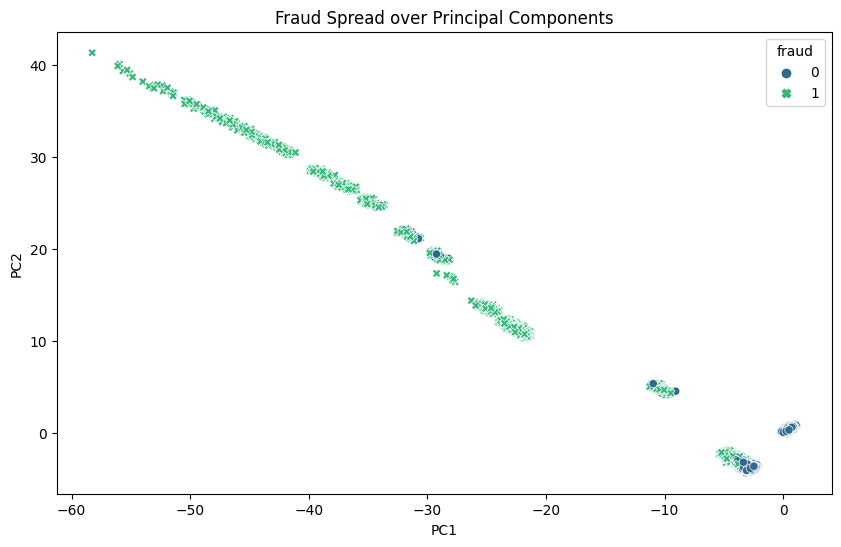


Evaluating: {'eps': 0.5, 'fraud_threshold': 0.1, 'min_samples': 5}
[2025-07-14 04:41:23.267] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 5294 -> 4518. Using the larger integer type might result in better performance

=== Training Fold 0 Results ===
Training Fold 0 Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  469325     163
Fraud        5694      78
Recall: 0.0135 | Precision: 0.3237
F1: 0.0259 | AUC: 0.5066

=== Test Fold 0 Results ===
Test Fold 0 Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud  116712     676
Fraud         941     487
Recall: 0.3410 | Precision: 0.4187
F1: 0.3759 | AUC: 0.6676
[2025-07-14 04:42:13.931] [CUML] [warning] Batch size limited by the chosen integer type (4 bytes). 5294 -> 4518. Using the larger integer type might result in better performance

=== Training Fold 1 Results ===
Training Fold 1 Confusion Matrix:
         Predicted
         Not Fraud  Fraud
Actual
N

In [4]:
best_model = main()